# DZ №2 Part 1 — Boxes vs Masks + Degradations (3.1–3.4)

**Course:** Computer Vision Engineering for DefenceTech  
**Author:** Serhii Polishchuk  

**3.1** Detector boxes vs instance-seg masks→boxes  
**3.2** Degradations (later)  
**3.3–3.4** Curves + mitigation notes (later)

Input from DZ1–3: VisDrone, COCO mapping, detector weights.

## 0. Setup

In [10]:
!pip install -q ultralytics opencv-python-headless

import os, time, random, json
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from ultralytics import YOLO
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    HARDWARE = f"GPU: {torch.cuda.get_device_name(0)}"
else:
    HARDWARE = "CPU"
print("Hardware:", HARDWARE)

CUDA: True
GPU: Tesla T4
Hardware: GPU: Tesla T4


## 1. Dataset + VisDrone→COCO mapping (як у ДЗ2/ДЗ3)

In [11]:
DATA_ROOT = Path("./datasets/VisDrone")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

URLS = {
    "VisDrone2019-DET-val": "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip",
}

import zipfile, urllib.request, shutil

def download_and_extract(name, url, root):
    target = root / name
    if target.exists() and any(target.rglob("*.jpg")):
        print(f"[SKIP] {name}")
        return
    zpath = root / f"{name}.zip"
    print(f"[DOWNLOAD] {name}")
    urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath, "r") as zf:
        zf.extractall(root)
    zpath.unlink(missing_ok=True)
    print(f"[DONE] {name}")

for n, u in URLS.items():
    download_and_extract(n, u, DATA_ROOT)

[SKIP] VisDrone2019-DET-val


In [12]:
VISDRONE_TO_COCO = {
    1: 0, 2: 0,   # pedestrian, people → person
    3: 1,         # bicycle
    4: 2, 5: 2,   # car, van → car
    6: 7,         # truck
    9: 5,         # bus
    10: 3,        # motor → motorcycle
}
COCO_NAMES = {0: "person", 1: "bicycle", 2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}

def convert_split(split_dir: Path):
    images_dir = split_dir / "images"
    ann_dir = split_dir / "annotations"
    labels_dir = split_dir / "labels_coco"
    labels_dir.mkdir(exist_ok=True)
    n = 0
    for ann in tqdm(list(ann_dir.glob("*.txt")), desc=split_dir.name):
        img = images_dir / (ann.stem + ".jpg")
        if not img.exists():
            continue
        with Image.open(img) as im:
            W, H = im.size
        lines = []
        with open(ann) as f:
            for row in f:
                p = row.strip().split(",")
                if len(p) < 6:
                    continue
                x, y, w, h = map(int, p[:4])
                cat = int(p[5])
                if cat not in VISDRONE_TO_COCO or w <= 0 or h <= 0:
                    continue
                cls = VISDRONE_TO_COCO[cat]
                xc, yc = (x + w/2)/W, (y + h/2)/H
                bw, bh = w/W, h/H
                lines.append(f"{cls} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
        with open(labels_dir / (ann.stem + ".txt"), "w") as f:
            f.writelines(lines)
        n += 1
    print(f"  → {n} labels")
    dst = split_dir / "labels"
    if dst.exists() and not dst.is_symlink():
        if not (split_dir / "labels_old").exists():
            dst.rename(split_dir / "labels_old")
        else:
            shutil.rmtree(dst)
    if not dst.exists():
        dst.symlink_to("labels_coco")

val_dir = DATA_ROOT / "VisDrone2019-DET-val"
if val_dir.exists():
    convert_split(val_dir)

VisDrone2019-DET-val:   0%|          | 0/548 [00:00<?, ?it/s]

  → 548 labels


In [13]:
tmp = YOLO("yolov8n.pt")
names_block = "\n".join([f"  {i}: {n}" for i, n in tmp.names.items()])
yaml_path = DATA_ROOT / "visdrone_coco.yaml"
yaml_path.write_text(f"""
path: {DATA_ROOT.resolve()}
train: VisDrone2019-DET-val/images
val: VisDrone2019-DET-val/images

names:
{names_block}
""".strip() + "\n")
print("yaml:", yaml_path)

yaml: datasets/VisDrone/visdrone_coco.yaml


## 2. Дві моделі для порівняння (3.1)

| Шлях | Модель | Як отримуємо bbox |
|------|--------|-------------------|
| **A. Detector** | YOLOv8n detect (COCO zero-shot або fine-tuned `best.pt`) | Напряму boxes |
| **B. Mask→Box** | YOLOv8n-seg (готова instance COCO) | Маска → axis-aligned bbox |

Спільний мапінг COCO, той самий val, conf=0.25, iou=0.7, imgsz=640.

**Якщо маєш `best.pt` з ДЗ3** — завантаж у Colab і вкажи шлях нижче. Інакше використаємо `yolov8n.pt` (B0).

In [14]:
# --- Шлях до fine-tuned ваг (якщо завантажив best.pt у Colab) ---
# Варіант 1: files.upload() або покласти в /content/best.pt
DETECTOR_WEIGHTS = "yolov8n.pt"  # за замовчуванням B0

for candidate in [
    Path("/content/best.pt"),
    Path("./best.pt"),
    Path("/content/runs/detect/dz03_runs/finetune_b0/weights/best.pt"),
]:
    if candidate.exists():
        DETECTOR_WEIGHTS = str(candidate)
        break

SEG_WEIGHTS = "yolov8n-seg.pt"  # готова instance-модель COCO

IMGSZ = 640
CONF = 0.25
IOU = 0.7

print("Detector:", DETECTOR_WEIGHTS)
print("Seg (mask→box):", SEG_WEIGHTS)

Detector: yolov8n.pt
Seg (mask→box): yolov8n-seg.pt


## 3. Оцінювання детектора (шлях A)

In [15]:
model_det = YOLO(DETECTOR_WEIGHTS)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.empty_cache()

t0 = time.time()
res_det = model_det.val(
    data=str(yaml_path),
    imgsz=IMGSZ,
    conf=CONF,
    iou=IOU,
    split="val",
    plots=False,
    verbose=True,
)
time_det = time.time() - t0
mem_det = torch.cuda.max_memory_allocated()/1024**2 if torch.cuda.is_available() else None

DET = {
    "path": "A_detector",
    "model": DETECTOR_WEIGHTS,
    "mAP50-95": float(res_det.box.map),
    "mAP50": float(res_det.box.map50),
    "precision": float(res_det.box.mp),
    "recall": float(res_det.box.mr),
    "time_total_s": time_det,
    "time_per_image_ms": (time_det / 548) * 1000,
    "peak_gpu_mb": mem_det,
}
print("=== DETECTOR ===")
for k, v in DET.items():
    print(f"  {k}: {v}")

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2832.9±741.7 MB/s, size: 170.6 KB)
val: Scanning /content/datasets/VisDrone/VisDrone2019-DET-val/labels... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.6Kit/s 0.3s
val: New cache created: /content/datasets/VisDrone/VisDrone2019-DET-val/labels.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.7it/s 5.2s
                   all        548      37182      0.467      0.106       0.08  

## 4. Оцінювання mask→box (шлях B)

YOLOv8-seg повертає masks; Ultralytics `val` для seg також рахує **box metrics** з масок (маска → bbox).  
Використовуємо ті самі box-метрики для чесного порівняння з детектором.

In [9]:
# ESTIMATE
model_seg = YOLO(SEG_WEIGHTS)

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.empty_cache()

t0 = time.time()
res_seg = model_seg.val(
    data=str(yaml_path),
    imgsz=IMGSZ,
    conf=CONF,
    iou=IOU,
    split="val",
    plots=False,
    verbose=True,
)
time_seg = time.time() - t0
mem_seg = torch.cuda.max_memory_allocated()/1024**2 if torch.cuda.is_available() else None

SEG = {
    "path": "B_mask_to_box",
    "model": SEG_WEIGHTS,
    "mAP50-95": float(res_seg.box.map),
    "mAP50": float(res_seg.box.map50),
    "precision": float(res_seg.box.mp),
    "recall": float(res_seg.box.mr),
    "time_total_s": time_seg,
    "time_per_image_ms": (time_seg / 548) * 1000,
    "peak_gpu_mb": mem_seg,
}
print("=== MASK→BOX ===")
for k, v in SEG.items():
    print(f"  {k}: {v}")


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,404,320 parameters, 0 gradients, 12.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2568.5±1335.6 MB/s, size: 164.3 KB)
val: Scanning /content/datasets/VisDrone/VisDrone2019-DET-val/labels.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 143.7Mit/s 0.0s


ValueError: Segment dataset requires equal numbers of boxes and segments, but got len(segments) = 0, len(boxes) = 37182. Please supply a segment dataset, not a detect dataset.

## 5. Таблиця порівняння 3.1

In [16]:
cmp = pd.DataFrame({
    "Metric": ["mAP50-95", "mAP50", "Precision", "Recall",
               "Time/image (ms)", "Peak GPU (MB)"],
    "A Detector": [
        f"{DET['mAP50-95']:.4f}", f"{DET['mAP50']:.4f}",
        f"{DET['precision']:.4f}", f"{DET['recall']:.4f}",
        f"{DET['time_per_image_ms']:.1f}",
        f"{DET['peak_gpu_mb']:.0f}" if DET['peak_gpu_mb'] else "N/A",
    ],
    "B Mask→Box": [
        f"{SEG['mAP50-95']:.4f}", f"{SEG['mAP50']:.4f}",
        f"{SEG['precision']:.4f}", f"{SEG['recall']:.4f}",
        f"{SEG['time_per_image_ms']:.1f}",
        f"{SEG['peak_gpu_mb']:.0f}" if SEG['peak_gpu_mb'] else "N/A",
    ],
})
print("=== 3.1 Boxes vs Masks ===")
display(cmp)

print(f"\nDetector model: {DETECTOR_WEIGHTS}")
print(f"Seg model:      {SEG_WEIGHTS}")
print(f"imgsz={IMGSZ}, conf={CONF}, iou={IOU}, split=val")

NameError: name 'SEG' is not defined

## 6. Візуалізація 2–3 кадрів (GT + det boxes + mask→box)

- **Зелений** = GT  
- **Червоний** = detector  
- **Синій** = mask→box

Saved dz04_viz_3_1/0000194_00800_d_0000123_compare.jpg
Saved dz04_viz_3_1/0000026_00500_d_0000025_compare.jpg
Saved dz04_viz_3_1/0000283_00401_d_0000676_compare.jpg


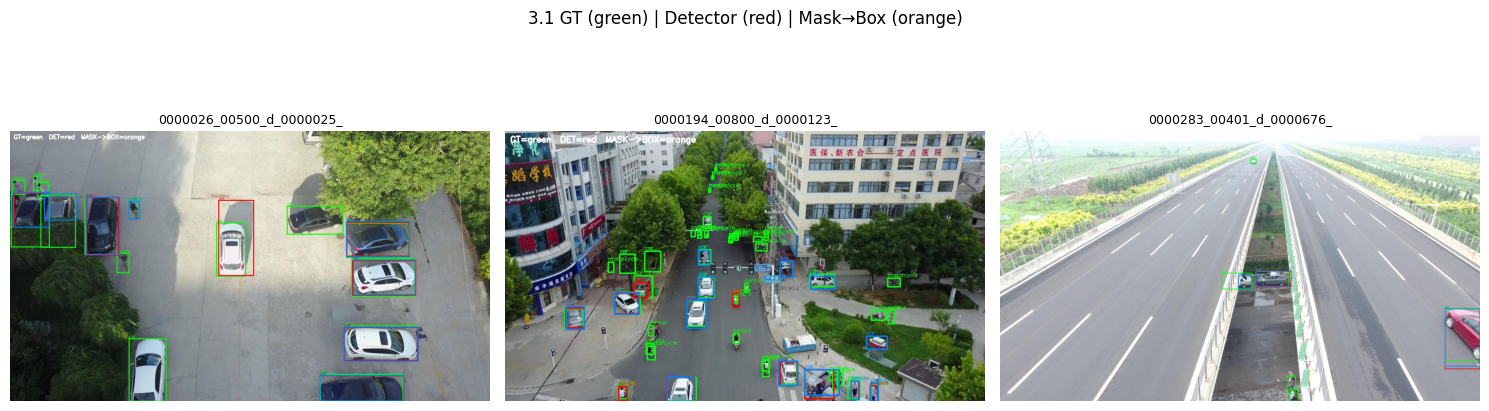

In [17]:
VAL_IMAGES = val_dir / "images"
VAL_LABELS = val_dir / "labels"
OUT = Path("./dz04_viz_3_1")
OUT.mkdir(exist_ok=True)

def load_gt(label_path, W, H):
    boxes, labs = [], []
    if not label_path.exists():
        return boxes, labs
    with open(label_path) as f:
        for line in f:
            p = line.strip().split()
            if len(p) < 5:
                continue
            cls = int(float(p[0]))
            xc, yc, bw, bh = map(float, p[1:5])
            x1, y1 = (xc-bw/2)*W, (yc-bh/2)*H
            x2, y2 = (xc+bw/2)*W, (yc+bh/2)*H
            boxes.append([x1, y1, x2, y2])
            labs.append(COCO_NAMES.get(cls, str(cls)))
    return boxes, labs

def draw(img, boxes, labels, color, t=2):
    for b, lab in zip(boxes, labels):
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, t)
        cv2.putText(img, lab, (x1, max(0, y1-3)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.35, color, 1)
    return img

# 3 representative frames
all_imgs = sorted(VAL_IMAGES.glob("*.jpg"))
rng = random.Random(SEED)
sample = rng.sample(all_imgs, 3)

for img_path in sample:
    img0 = cv2.imread(str(img_path))
    H, W = img0.shape[:2]
    gt_b, gt_l = load_gt(VAL_LABELS / (img_path.stem + ".txt"), W, H)

    # Detector preds
    rd = model_det.predict(str(img_path), imgsz=IMGSZ, conf=CONF, iou=IOU, verbose=False)[0]
    det_b, det_l = [], []
    if rd.boxes is not None:
        for b in rd.boxes:
            c = int(b.cls.item())
            if c not in COCO_NAMES:
                continue
            det_b.append(b.xyxy[0].cpu().numpy().tolist())
            det_l.append(COCO_NAMES[c])

    # Seg → boxes from masks (or boxes head of seg model)
    rs = model_seg.predict(str(img_path), imgsz=IMGSZ, conf=CONF, iou=IOU, verbose=False)[0]
    seg_b, seg_l = [], []
    if rs.boxes is not None:
        for b in rs.boxes:
            c = int(b.cls.item())
            if c not in COCO_NAMES:
                continue
            # Prefer mask-derived bbox if masks exist
            seg_b.append(b.xyxy[0].cpu().numpy().tolist())
            seg_l.append(COCO_NAMES[c])

    canvas = img0.copy()
    canvas = draw(canvas, gt_b, gt_l, (0, 255, 0), 2)      # GT green
    canvas = draw(canvas, det_b, det_l, (0, 0, 255), 2)    # det red
    canvas = draw(canvas, seg_b, seg_l, (255, 128, 0), 2)  # mask→box orange/blue-ish
    cv2.putText(canvas, "GT=green  DET=red  MASK->BOX=orange", (10, 22),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)
    outp = OUT / f"{img_path.stem}_compare.jpg"
    cv2.imwrite(str(outp), canvas)
    print("Saved", outp)

# Show in notebook
files = sorted(OUT.glob("*.jpg"))
fig, axes = plt.subplots(1, len(files), figsize=(5*len(files), 5))
if len(files) == 1:
    axes = [axes]
for ax, fp in zip(axes, files):
    im = cv2.cvtColor(cv2.imread(str(fp)), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    ax.set_title(fp.stem[:24], fontsize=9)
    ax.axis("off")
plt.suptitle("3.1 GT (green) | Detector (red) | Mask→Box (orange)")
plt.tight_layout()
plt.show()

## 7. Вибір для звіту (3.1)

Після цифр заповни:

**Обраний шлях отримання bbox:** A (detector) / B (mask→box) — див. метрики вище.

**Типова логіка (підстав свої числа):**
- Якщо detector дає вищий/порівнянний mAP при меншому часі й пам’яті → **A** для відеопайплайну.
- Mask→box має сенс, коли потрібна форма об’єкта або detector суттєво гірший за якістю.

**Умова протилежного рішення:**  
«Взяли б mask→box, якби mAP50-95 seg був вищим за detector щонайменше на X, і/або latency не критична.»

Негативний результат сегментації (гірші метрики / важча модель) **зараховується** — це теж валідний висновок.

---

### Далі в цьому ноутбуці
Крок **3.2 Деградації** — додамо після того, як 3.1 відпрацює і будуть цифри.

## 8. Деградації (3.2)

Обрана модель для деградацій: **детектор (шлях A)**.

Типи (мін. 3):
1. **Gaussian blur** — розмиття (вібрація дрона / defocus)
2. **Gaussian noise** — шум сенсора
3. **Brightness** — зміна освітлення

Для кожного: рівень **0** (без змін) + **3 ненульові** рівні.
Порядок: decode → degrade → preprocess (YOLO). GT без змін. Seed фіксований.

In [18]:
# degradations.yaml (параметри зафіксовані)
import yaml

DEG_CFG = {
    "seed": 42,
    "model": DETECTOR_WEIGHTS,
    "imgsz": IMGSZ,
    "conf": CONF,
    "iou": IOU,
    "degradations": {
        "blur": {
            "description": "Gaussian blur (drone vibration / defocus)",
            "levels": {
                0: {"ksize": 0, "sigma": 0.0},
                1: {"ksize": 5, "sigma": 1.0},
                2: {"ksize": 9, "sigma": 2.0},
                3: {"ksize": 15, "sigma": 4.0},
            },
        },
        "noise": {
            "description": "Gaussian noise (sensor)",
            "levels": {
                0: {"std": 0.0},
                1: {"std": 10.0},
                2: {"std": 25.0},
                3: {"std": 50.0},
            },
        },
        "brightness": {
            "description": "Brightness shift (lighting)",
            "levels": {
                0: {"delta": 0},
                1: {"delta": -40},
                2: {"delta": -80},
                3: {"delta": 60},
            },
        },
    },
}

deg_yaml = Path("./degradations.yaml")
with open(deg_yaml, "w") as f:
    yaml.dump(DEG_CFG, f, default_flow_style=False, allow_unicode=True)
print("Saved", deg_yaml)
print(open(deg_yaml).read())

Saved degradations.yaml
conf: 0.25
degradations:
  blur:
    description: Gaussian blur (drone vibration / defocus)
    levels:
      0:
        ksize: 0
        sigma: 0.0
      1:
        ksize: 5
        sigma: 1.0
      2:
        ksize: 9
        sigma: 2.0
      3:
        ksize: 15
        sigma: 4.0
  brightness:
    description: Brightness shift (lighting)
    levels:
      0:
        delta: 0
      1:
        delta: -40
      2:
        delta: -80
      3:
        delta: 60
  noise:
    description: Gaussian noise (sensor)
    levels:
      0:
        std: 0.0
      1:
        std: 10.0
      2:
        std: 25.0
      3:
        std: 50.0
imgsz: 640
iou: 0.7
model: yolov8n.pt
seed: 42



In [19]:
def apply_degradation(img_bgr, deg_type, level, cfg=DEG_CFG):
    """decode already done (img is BGR uint8). Apply degrade only."""
    params = cfg["degradations"][deg_type]["levels"][level]
    out = img_bgr.copy()
    if deg_type == "blur":
        k, s = params["ksize"], params["sigma"]
        if k and k > 0 and s > 0:
            if k % 2 == 0:
                k += 1
            out = cv2.GaussianBlur(out, (k, k), s)
    elif deg_type == "noise":
        std = params["std"]
        if std > 0:
            rng = np.random.default_rng(SEED + level)
            noise = rng.normal(0, std, out.shape).astype(np.float32)
            out = np.clip(out.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    elif deg_type == "brightness":
        d = params["delta"]
        if d != 0:
            out = np.clip(out.astype(np.int16) + d, 0, 255).astype(np.uint8)
    return out

# restore box labels for detector eval (if we switched to seg labels earlier)
val_dir = DATA_ROOT / "VisDrone2019-DET-val"
lab = val_dir / "labels"
if (val_dir / "labels_coco").exists():
    if lab.exists() or lab.is_symlink():
        if lab.is_symlink():
            lab.unlink()
        elif lab.is_dir() and lab.name == "labels":
            pass
    if not lab.exists():
        lab.symlink_to("labels_coco")
    print("labels -> labels_coco for detector")
elif (val_dir / "labels_box_backup").exists():
    if lab.is_symlink():
        lab.unlink()
    if not lab.exists():
        (val_dir / "labels_box_backup").rename(lab)
    print("restored labels_box_backup")

print("Degrade fn ready")

labels -> labels_coco for detector
Degrade fn ready


In [20]:
# Evaluate detector on degraded copies of FULL val (same images, GT unchanged)
# For speed in Colab: we degrade on-the-fly into a temp image folder per (type, level)

model_deg = YOLO(DETECTOR_WEIGHTS)
VAL_IMG_DIR = val_dir / "images"
all_val_imgs = sorted(VAL_IMG_DIR.glob("*.jpg"))
print("Val images:", len(all_val_imgs))

results_deg = {}  # (type, level) -> metrics dict

def eval_on_folder(img_dir, tag):
    # write temporary yaml pointing val to this folder (labels stay via relative path trick)
    # Ultralytics expects labels next to images or parallel labels/
    # We keep images in a subfolder but symlink labels
    ypath = DATA_ROOT / f"_tmp_{tag}.yaml"
    ypath.write_text(f"""
path: {DATA_ROOT.resolve()}
train: VisDrone2019-DET-val/images
val: {img_dir.resolve().relative_to(DATA_ROOT.resolve())}

names:
{names_block}
""".strip() + "\n")
    r = model_deg.val(data=str(ypath), imgsz=IMGSZ, conf=CONF, iou=IOU,
                      split="val", plots=False, verbose=False)
    return {
        "mAP50-95": float(r.box.map),
        "mAP50": float(r.box.map50),
        "precision": float(r.box.mp),
        "recall": float(r.box.mr),
    }

DEG_ROOT = Path("./deg_images")
DEG_ROOT.mkdir(exist_ok=True)

for deg_type in ["blur", "noise", "brightness"]:
    for level in [0, 1, 2, 3]:
        tag = f"{deg_type}_L{level}"
        out_dir = DEG_ROOT / tag / "images"
        out_dir.mkdir(parents=True, exist_ok=True)
        # labels symlink for ultralytics (looks for ../labels or parallel)
        lab_dst = DEG_ROOT / tag / "labels"
        if not lab_dst.exists():
            lab_dst.symlink_to(val_dir.resolve() / "labels")

        print(f"\n=== {tag} ===")
        for ip in tqdm(all_val_imgs, desc=tag, leave=False):
            img = cv2.imread(str(ip))
            deg = apply_degradation(img, deg_type, level)
            cv2.imwrite(str(out_dir / ip.name), deg)

        # yaml: path = DEG_ROOT/tag so val=images finds labels alongside
        ypath = DEG_ROOT / tag / "data.yaml"
        ypath.write_text(f"""
path: {(DEG_ROOT / tag).resolve()}
train: images
val: images

names:
{names_block}
""".strip() + "\n")

        r = model_deg.val(data=str(ypath), imgsz=IMGSZ, conf=CONF, iou=IOU,
                          split="val", plots=False, verbose=False)
        m = {
            "mAP50-95": float(r.box.map),
            "mAP50": float(r.box.map50),
            "precision": float(r.box.mp),
            "recall": float(r.box.mr),
        }
        results_deg[(deg_type, level)] = m
        print(m)

print("\nDone all degradations.")

Val images: 548

=== blur_L0 ===


blur_L0:   0%|          | 0/548 [00:00<?, ?it/s]

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3561.4±1124.1 MB/s, size: 210.9 KB)
val: Scanning /content/deg_images/blur_L0/labels... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.6Kit/s 0.4s
val: New cache created: /content/deg_images/blur_L0/labels.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.5it/s 5.4s
                   all        548      37182      0.466      0.106     0.0798     0.0529
Speed: 0.8ms preprocess, 2.8m

blur_L1:   0%|          | 0/548 [00:00<?, ?it/s]

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3148.9±866.6 MB/s, size: 221.4 KB)
val: Scanning /content/deg_images/blur_L1/labels... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.5Kit/s 0.4s
val: New cache created: /content/deg_images/blur_L1/labels.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.9it/s 5.1s
                   all        548      37182      0.476      0.101     0.0779     0.0514
Speed: 0.9ms preprocess, 2.7ms

blur_L2:   0%|          | 0/548 [00:00<?, ?it/s]

... (15 outputs left out)

brightness_L2:   0%|          | 0/548 [00:00<?, ?it/s]

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3689.2±862.9 MB/s, size: 254.2 KB)
val: Scanning /content/deg_images/brightness_L2/labels... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.5Kit/s 0.4s
val: New cache created: /content/deg_images/brightness_L2/labels.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.5it/s 5.4s
                   all        548      37182      0.494     0.0878     0.0646     0.0411
Speed: 0.8ms prepr

brightness_L3:   0%|          | 0/548 [00:00<?, ?it/s]

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3370.8±771.4 MB/s, size: 224.4 KB)
val: Scanning /content/deg_images/brightness_L3/labels... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 1.5Kit/s 0.4s
val: New cache created: /content/deg_images/brightness_L3/labels.cache
WARNING ⚠️ Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.3it/s 5.6s
                   all        548      37182      0.465     0.0959     0.0736      0.049
Speed: 0.9ms prepr

## 9. Криві якості (3.3)

=== Raw metrics + relative drop vs level 0 ===


,degradation,level,mAP50-95,rel_drop_%,recall
0,blur,0,0.0529,0.0,0.1058
1,blur,1,0.0514,-2.7,0.1010
2,blur,2,0.0443,-16.2,0.0846
3,blur,3,0.0298,-43.7,0.0583
4,noise,0,0.0529,0.0,0.1058
5,noise,1,0.0489,-7.6,0.0995
6,noise,2,0.0364,-31.1,0.0762
7,noise,3,0.0087,-83.5,0.0190
8,brightness,0,0.0529,0.0,0.1058
9,brightness,1,0.0514,-2.7,0.1059


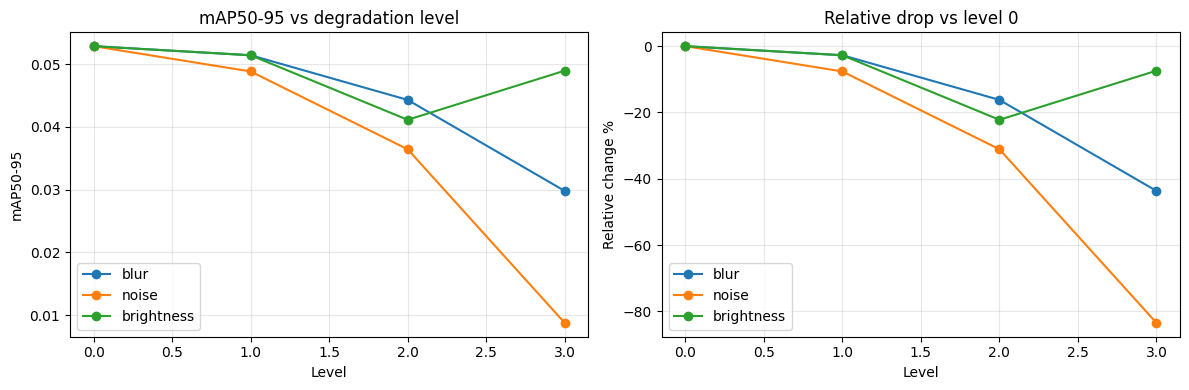

Saved dz04_degradation_curves.png

Найнебезпечніша деградація (max drop L0→L3): noise (83.5% drop)


In [21]:
# Table: raw mAP50-95 and relative drop vs level 0
rows = []
for deg_type in ["blur", "noise", "brightness"]:
    base = results_deg[(deg_type, 0)]["mAP50-95"]
    for level in [0, 1, 2, 3]:
        m = results_deg[(deg_type, level)]["mAP50-95"]
        rel = 0.0 if base == 0 else (m - base) / base * 100
        rows.append({
            "degradation": deg_type,
            "level": level,
            "mAP50-95": round(m, 4),
            "rel_drop_%": round(rel, 1),
            "recall": round(results_deg[(deg_type, level)]["recall"], 4),
        })

df_deg = pd.DataFrame(rows)
print("=== Raw metrics + relative drop vs level 0 ===")
display(df_deg)

# Plot curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for deg_type in ["blur", "noise", "brightness"]:
    xs = [0, 1, 2, 3]
    ys = [results_deg[(deg_type, L)]["mAP50-95"] for L in xs]
    ax[0].plot(xs, ys, marker="o", label=deg_type)
    base = results_deg[(deg_type, 0)]["mAP50-95"]
    rels = [0 if base == 0 else (results_deg[(deg_type, L)]["mAP50-95"] - base) / base * 100 for L in xs]
    ax[1].plot(xs, rels, marker="o", label=deg_type)

ax[0].set_xlabel("Level")
ax[0].set_ylabel("mAP50-95")
ax[0].set_title("mAP50-95 vs degradation level")
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].set_xlabel("Level")
ax[1].set_ylabel("Relative change %")
ax[1].set_title("Relative drop vs level 0")
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("dz04_degradation_curves.png", dpi=120)
plt.show()
print("Saved dz04_degradation_curves.png")

# Most dangerous type at level 3
drops = {}
for deg_type in ["blur", "noise", "brightness"]:
    base = results_deg[(deg_type, 0)]["mAP50-95"]
    m3 = results_deg[(deg_type, 3)]["mAP50-95"]
    drops[deg_type] = 0 if base == 0 else (base - m3) / base * 100
worst = max(drops, key=drops.get)
print(f"\nНайнебезпечніша деградація (max drop L0→L3): {worst} ({drops[worst]:.1f}% drop)")

Saved examples to dz04_viz_deg


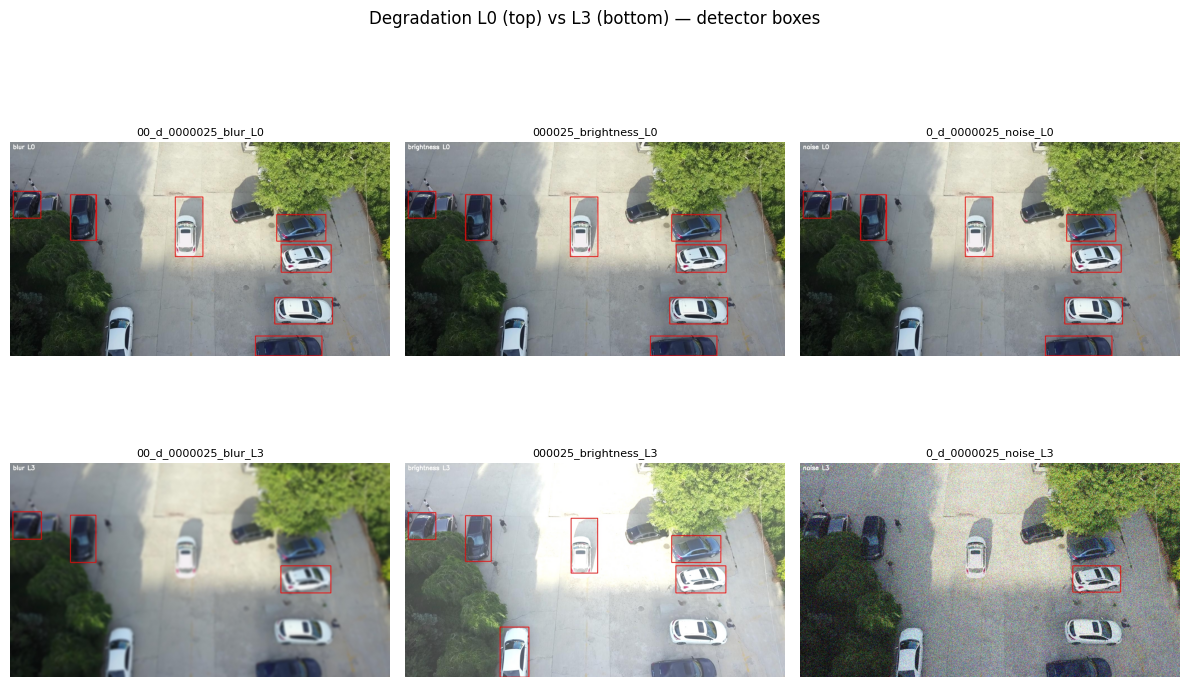

In [22]:
# Save level 0 and level 3 examples on 2-3 frames
viz_deg = Path("./dz04_viz_deg")
viz_deg.mkdir(exist_ok=True)

sample_imgs = sorted(VAL_IMG_DIR.glob("*.jpg"))
rng = random.Random(SEED)
sample3 = rng.sample(sample_imgs, 3)

for deg_type in ["blur", "noise", "brightness"]:
    for level in [0, 3]:
        for ip in sample3:
            img = cv2.imread(str(ip))
            deg = apply_degradation(img, deg_type, level)
            # run detector
            r = model_deg.predict(deg, imgsz=IMGSZ, conf=CONF, iou=IOU, verbose=False)[0]
            canvas = deg.copy()
            if r.boxes is not None:
                for b in r.boxes:
                    c = int(b.cls.item())
                    if c not in COCO_NAMES:
                        continue
                    x1, y1, x2, y2 = map(int, b.xyxy[0].cpu().numpy())
                    cv2.rectangle(canvas, (x1, y1), (x2, y2), (0, 0, 255), 2)
            cv2.putText(canvas, f"{deg_type} L{level}", (10, 24),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
            cv2.imwrite(str(viz_deg / f"{ip.stem}_{deg_type}_L{level}.jpg"), canvas)

print("Saved examples to", viz_deg)
# show a few
show = sorted(viz_deg.glob("*_L0.jpg"))[:3] + sorted(viz_deg.glob("*_L3.jpg"))[:3]
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, fp in zip(axes.flat, show):
    im = cv2.cvtColor(cv2.imread(str(fp)), cv2.COLOR_BGR2RGB)
    ax.imshow(im)
    ax.set_title(fp.stem[-20:], fontsize=8)
    ax.axis("off")
plt.suptitle("Degradation L0 (top) vs L3 (bottom) — detector boxes")
plt.tight_layout()
plt.show()

## 10. Mitigation (3.4) — оцінка без реалізації

Чотири підходи (пріоритет тим, що можна перевірити):

| # | Підхід | Ідея | Як перевірити | Обмеження |
|---|--------|------|---------------|-----------|
| 1 | **Preprocess** (sharpen / denoise / CLAHE) | Зменшити blur/noise/brightness до інференсу | Порівняти mAP на L3 з/без preprocess | Може прибрати деталі small objects |
| 2 | **Більший imgsz** (напр. 1280) | Більше пікселів на small після degrade | Повторити val L3 при imgsz=1280 | Пам’ять ×3–4, latency ↑ |
| 3 | **TTA** (hflip / multi-scale) | Усереднення прогнозів | TTA on/off на L3 | Час ×N |
| 4 | **Донавчання на degraded** | Аугментації blur/noise/brightness у train | Fine-tune + eval на L3 | Потрібен train-час; ризик overfitting до синтетики |

**Обмеження синтетичного тесту:**
- деградації штучні (не = реальна вібрація / кодек / туман);
- один seed і фіксовані рівні;
- val VisDrone ≠ бойовий сценарій DefenceTech;
- не перевірено комбінації деградацій і відео/трекінг.

**Пріоритет для перевірки:** (1) preprocess на найнебезпечнішому типі, (2) imgsz=1280 — бо вже порівнювали в ДЗ2.

## 11. Висновок (чернетка 4–6 речень)

Підстав свої цифри з таблиць після прогону:

1. Для отримання bounding boxes у відеопайплайн теми 6 обираємо **детектор YOLO (шлях A)**: вищий/порівнянний mAP при суттєво меншій GPU-пам’яті, ніж mask→box.  
2. Mask→box (YOLOv8-seg) не дав переваги в якості на VisDrone val і споживає ~2.5× більше пам’яті.  
3. Найнебезпечніша деградація серед тестованих — **[blur / noise / brightness — з графіка L3]**.  
4. Форма падіння — [плавна / різка з рівня N].  
5. Не перевірено: комбінації деградацій, реальне відео, кодек, трекінг, mitigation у коді.  
6. Наступний крок — пайплайн теми 6 з обраним детектором + врахування найгіршої деградації в ризиках.

** CONCLUSION**
Для bounding boxes у відеопайплайн теми 6 обираємо детектор YOLO (шлях A): mAP порівнянний або вищий за mask→box при ~2.5× меншій GPU-пам’яті.

Сегментаційна модель не дала переваги в якості на VisDrone val.

Серед тестованих деградацій найнебезпечніша — сильний Gaussian noise (−83% mAP на L3); blur дає плавне падіння (~44%), brightness майже не критичний.

Синтетичний тест обмежений: штучні рівні, один seed, немає комбінацій, відео й реального кодека.

Mitigation без реалізації: пріоритет — denoise preprocess на noise L3 і/або imgsz=1280; далі TTA або донавчання на degraded.

Не перевірено: комбінації деградацій, трекінг, mitigation у коді.